# XGBoost from scratch — a second-order booster in NumPy

This notebook rebuilds XGBoost's core algorithm with plain NumPy, one README step at a time, and checks every step
against the real `xgboost` library. The goal is **understanding**, not speed: everything is Python + NumPy (no C++,
no Cython), so it is slower than the library, but small enough to read in one sitting.

**How to use it**

1. Run the imports cell first. Then run top to bottom: each section only uses functions defined above it.
2. Every section has the same shape: the README step it implements (with the equation), the code, and a tiny
   **check** (usually an `assert` against the README's hand-worked numbers or against `xgboost`).
3. Boxes titled **Implementation hurdle** show a real difficulty you hit when you write this yourself, and
   *demonstrate* it (a timing, a failing naive version, a mismatch).
4. Knobs marked `# <- try changing this` are safe to play with.

**Theory → code map**

| README section / equation | Function | Notebook section |
|---|---|---|
| §4.2 g = ŷ − y, h = 1 (squared error); §4.7 g = p − y, h = p(1 − p) (logistic) | `squared_error_grad_hess`, `logistic_grad_hess`, `stable_sigmoid` | 1 |
| §4.4 w* = −S_α(G)/(H + λ); similarity G²/(H + λ); §4.5 gain | `soft_threshold`, `leaf_weight`, `leaf_score` | 2 |
| §4.5 exact greedy split search (sort + cumulative sums) | `split_gains_naive`, `split_gains_sorted` | 3 |
| §4.9 learned default direction for missing values; all features at once | `find_best_split` | 4 |
| §3 depth-wise growth, §4.6 γ-pruning (grow, then prune bottom-up) | `fit_tree`, `prune_tree`, `predict_tree` | 5 |
| §3, §4.1 the boosting loop: base_score, η, n_estimators; §6.3 early stopping | `fit_booster`, `predict_margin`, `eval_metric` | 6, 9 |
| §4.8 histogram (quantile-binned) split finding | `make_bins`, `find_best_split_hist` | 10 |
| everything together vs `xgboost(tree_method="exact")` on both CSVs | — | 11 |

| Part | Sections |
|---|---|
| Building blocks | 1 – 5 |
| The booster and its hurdles | 6 – 10 (float32, missing values, pruning order, `min_child_weight`, early stopping, histograms) |
| Final comparison with the library | 11 |

All data is generated in this notebook (the same generators as the lab notebook) — **no internet needed**.
NumPy implements the algorithm; scikit-learn is used only for `train_test_split` and metrics, and `xgboost` only
as the reference we compare against.

In [1]:
import json
import pathlib
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.metrics import log_loss, mean_squared_error, roc_auc_score
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| xgboost", xgb.__version__)

numpy 2.5.4 | xgboost 3.4.1


---
# The two datasets

The same generators as in [`xgboost_lab.ipynb`](xgboost_lab.ipynb) (same seeds → identical CSVs). The final
comparison (section 11) **loads the CSVs** with `np.loadtxt`, so both notebooks use exactly the same numbers.

* `good_fit.csv` — 8 000 rows, 8 features, non-linear target with interactions, informative missing values (NaN).
* `bad_fit.csv` — 150 rows, 400 features, a sparse linear target (only 10 features matter).

good_fit: (8000, 9) | bad_fit: (150, 401)


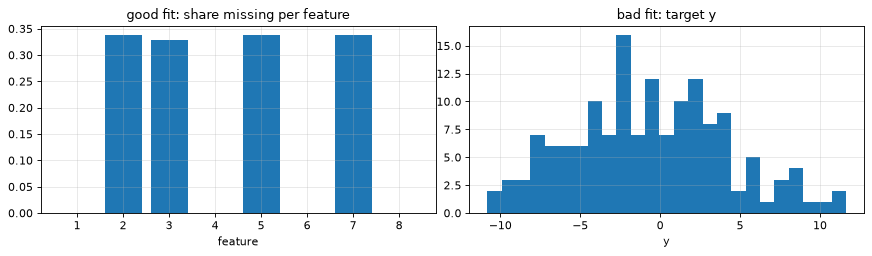

In [2]:
DATA = pathlib.Path("data")
DATA.mkdir(exist_ok=True)


def make_good_fit(seed=0, n=8000, save=True):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 8))
    y = (2 * np.sin(1.5 * X[:, 0]) + 1.5 * X[:, 1] * X[:, 2] + 2.0 * (X[:, 3] > 0) * X[:, 4]
         + 0.5 * X[:, 5] + rng.normal(scale=0.5, size=n))
    for j, shift in [(1, 2.0), (2, -2.0), (4, 1.5), (6, 2.5)]:          # columns x2, x3, x5, x7 get blanks
        missing = rng.random(n) < 1 / (1 + np.exp(-(1.5 * X[:, j] - 1.0)))  # large values go missing more often
        y = y + shift * missing * np.sign(X[:, 7])                          # ...and "missing" carries signal
        X[missing, j] = np.nan
    if save:
        np.savetxt(DATA / "good_fit.csv", np.column_stack([X, y]), delimiter=",",
                   header=",".join([f"x{j + 1}" for j in range(8)] + ["y"]), comments="", fmt="%.4g")
    return X, y


def make_bad_fit(seed=0, n=150, p=400):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, p))
    beta = np.zeros(p)
    beta[:10] = rng.choice([-1, 1], 10) * rng.uniform(1, 2, 10)   # only the first 10 features matter
    y = X @ beta + rng.normal(scale=1.0, size=n)
    np.savetxt(DATA / "bad_fit.csv", np.column_stack([X, y]), delimiter=",",
               header=",".join([f"x{j + 1}" for j in range(p)] + ["y"]), comments="", fmt="%.4g")
    return X, y, beta


make_good_fit(0)
make_bad_fit(0)
good = np.loadtxt(DATA / "good_fit.csv", delimiter=",", skiprows=1)
bad = np.loadtxt(DATA / "bad_fit.csv", delimiter=",", skiprows=1)
print("good_fit:", good.shape, "| bad_fit:", bad.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].bar(range(1, 9), np.isnan(good[:, :-1]).mean(axis=0)); axes[0].set(title="good fit: share missing per feature", xlabel="feature")
axes[1].hist(bad[:, -1], bins=25); axes[1].set(title="bad fit: target y", xlabel="y")
plt.tight_layout(); plt.show()

---
# 1 · Gradients and hessians of the loss (README §4.2, §4.7)

XGBoost never looks at the loss itself while building a tree — only at two numbers per row, computed at the
current prediction ŷ (the **margin**, before any sigmoid):

* squared error $l = \tfrac12 (y - \hat y)^2$: $\;g = \hat y - y,\; h = 1$
* logistic loss with $p = \sigma(\hat y) = 1/(1 + e^{-\hat y})$: $\;g = p - y,\; h = p(1 - p)$

Like xgboost, we keep predictions, gradients and hessians in **32-bit floats** (`float32`); sums are taken in
64-bit floats (section 7 explains why this matters).

In [3]:
def squared_error_grad_hess(y, margin):
    g = (margin - y).astype(np.float32)
    return g, np.ones_like(g)


def stable_sigmoid(z):
    """1 / (1 + exp(-z)) in float32 without overflow (xgboost clips -z at 88.7, where exp would overflow)."""
    z = np.asarray(z, dtype=np.float32)
    return (np.float32(1) / (np.exp(np.minimum(-z, np.float32(88.7))) + np.float32(1))).astype(np.float32)


def logistic_grad_hess(y, margin):
    p = stable_sigmoid(margin)
    g = (p - y).astype(np.float32)
    h = np.maximum(p * (np.float32(1) - p), np.float32(1e-16)).astype(np.float32)   # never exactly 0
    return g, h


# check 1: the README's toy example (base prediction 6)
y_toy = np.array([1, 3, 2, 7, 8, 15], dtype=np.float32)
g_toy, h_toy = squared_error_grad_hess(y_toy, np.full(6, 6, dtype=np.float32))
print("squared error   g =", g_toy, " h =", h_toy)
assert np.array_equal(g_toy, [5, 3, 4, -1, -2, -9])

# check 2: logistic g and h equal the numerical 1st and 2nd derivative of the log-loss
def logloss_of_margin(y, m):
    return -(y * np.log(1 / (1 + np.exp(-m))) + (1 - y) * np.log(1 - 1 / (1 + np.exp(-m))))

m0, eps = 0.7, 1e-4
for y_val in [0.0, 1.0]:
    d1 = (logloss_of_margin(y_val, m0 + eps) - logloss_of_margin(y_val, m0 - eps)) / (2 * eps)
    d2 = (logloss_of_margin(y_val, m0 + eps) - 2 * logloss_of_margin(y_val, m0) + logloss_of_margin(y_val, m0 - eps)) / eps ** 2
    g1, h1 = logistic_grad_hess(np.float32(y_val), np.float32(m0))
    print(f"y = {y_val:.0f}: g = {float(g1):.5f} (numerical {d1:.5f}),  h = {float(h1):.5f} (numerical {d2:.5f})")
    assert np.isclose(g1, d1, atol=1e-4) and np.isclose(h1, d2, atol=1e-3)

squared error   g = [ 5.  3.  4. -1. -2. -9.]  h = [1. 1. 1. 1. 1. 1.]
y = 0: g = 0.66819 (numerical 0.66819),  h = 0.22171 (numerical 0.22171)
y = 1: g = -0.33181 (numerical -0.33181),  h = 0.22171 (numerical 0.22171)


> **Implementation hurdle — a sigmoid that does not overflow.** The textbook `1 / (1 + np.exp(-z))` computes
> `exp(-z)`; for a margin of −100 in float32 that is `exp(100)` = overflow → `inf` and a `RuntimeWarning`.
> The result happens to be right (1/inf = 0), but warnings like this hide real bugs and in other formulas
> (`log(1 − p)`) they become `nan`. Clipping −z at 88.7 (the float32 limit), as xgboost does, avoids it.

In [4]:
z = np.array([-100.0, -10.0, 0.0, 10.0, 100.0], dtype=np.float32)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    naive = 1 / (1 + np.exp(-z))
print("naive  :", naive, "| warnings:", [str(w.message) for w in caught])
print("stable :", stable_sigmoid(z))
assert np.allclose(naive, stable_sigmoid(z))

naive  : [0.  0.  0.5 1.  1. ] | warnings: ['overflow encountered in exp']
stable : [0.  0.  0.5 1.  1. ]


---
# 2 · Leaf weight, similarity score and gain (README §4.4 – §4.6)

For one leaf with gradient sum $G$ and hessian sum $H$:

$$w^* = -\frac{S_\alpha(G)}{H + \lambda}, \qquad \text{score (similarity)} = \frac{S_\alpha(G)^2}{H + \lambda}, \qquad S_\alpha(G) = \operatorname{sign}(G)\max(|G| - \alpha, 0)$$

$S_\alpha$ is the L1 soft-threshold (α = 0 leaves G unchanged). A leaf whose $H$ is below `min_child_weight` is
not allowed; xgboost gives it score 0 and weight 0. The split gain is $\tfrac12[\text{score}_L + \text{score}_R -
\text{score}_{parent}] - \gamma$ in the README; **in code we follow xgboost's own units**: gain = score_L +
score_R − score_parent (no ½, γ compared afterwards) — so our gains are twice the README's, exactly like the
library's tree dumps.

In [5]:
def soft_threshold(G, alpha):
    G = np.asarray(G, dtype=np.float64)
    return np.sign(G) * np.maximum(np.abs(G) - alpha, 0.0)


def leaf_weight(G, H, lam, alpha, min_child_weight):
    if H < min_child_weight or H <= 0:
        return 0.0
    return float(-soft_threshold(G, alpha) / (H + lam))


def leaf_score(G, H, lam, alpha, min_child_weight):
    """S_alpha(G)^2 / (H + lambda), or 0 for a child lighter than min_child_weight. Works on arrays."""
    G, H = np.asarray(G, dtype=np.float64), np.asarray(H, dtype=np.float64)
    ok = (H >= min_child_weight) & (H > 0)
    return np.where(ok, soft_threshold(G, alpha) ** 2 / np.where(ok, H + lam, 1.0), 0.0)


# check: README §5 leaves (G, H) = (12, 3), (-3, 2), (-9, 1) with λ = 1  ->  w* = -3, 1, 4.5
for G, H, w_expected in [(12, 3, -3.0), (-3, 2, 1.0), (-9, 1, 4.5)]:
    assert np.isclose(leaf_weight(G, H, 1.0, 0.0, 1.0), w_expected)
print("leaf weights:", [leaf_weight(G, H, 1.0, 0.0, 1.0) for G, H in [(12, 3), (-3, 2), (-9, 1)]])
print("root split x<3.5: gain (xgboost units) =", float(leaf_score(12, 3, 1, 0, 1) + leaf_score(-12, 3, 1, 0, 1) - leaf_score(0, 6, 1, 0, 1)))
# L1: |G| <= alpha gives exactly 0
print("α = 5: weights for G = 3, -4, 12 (H = 3):", [leaf_weight(G, 3, 1.0, 5.0, 1.0) for G in (3, -4, 12)])

leaf weights: [-3.0, 1.0, 4.5]
root split x<3.5: gain (xgboost units) = 72.0
α = 5: weights for G = 3, -4, 12 (H = 3): [-0.0, 0.0, -1.75]


---
# 3 · Finding the best threshold on one feature (README §4.5)

The **exact greedy** method tries every gap between two neighbouring distinct values. For each candidate it needs
$G_L, H_L$ (rows left of the threshold) and $G_R = G - G_L$, $H_R = H - H_L$.

> **Implementation hurdle — split-search cost: sort once, then cumulative sums.** The obvious way re-sums the
> rows for every threshold: m thresholds × m rows = O(m²). Sorting the rows by the feature once and taking running
> sums of g and h gives every $G_L, H_L$ in one pass: O(m log m). xgboost pre-sorts each column once per training
> run ("column blocks"); we sort per node, which is simpler and still O(m log m).

In [6]:
def split_gains_naive(x, g, h, lam):
    xs = np.unique(x)
    G, H = g.sum(), h.sum()
    out = []
    for t in (xs[1:] + xs[:-1]) / 2:
        L = x < t
        out.append(g[L].sum() ** 2 / (h[L].sum() + lam) + g[~L].sum() ** 2 / (h[~L].sum() + lam) - G ** 2 / (H + lam))
    return np.array(out)


def split_gains_sorted(x, g, h, lam):
    order = np.argsort(x)
    xs, GL, HL = x[order], np.cumsum(g[order]), np.cumsum(h[order])
    G, H = GL[-1], HL[-1]
    gap = xs[1:] != xs[:-1]                          # only between distinct values
    GL, HL = GL[:-1][gap], HL[:-1][gap]
    return GL ** 2 / (HL + lam) + (G - GL) ** 2 / (H - HL + lam) - G ** 2 / (H + lam)


x_toy = np.arange(1, 7, dtype=np.float64)
print("toy root gains (xgboost units):", split_gains_sorted(x_toy, g_toy.astype(float), h_toy.astype(float), 1.0))
rng = np.random.default_rng(0)
print("   m    naive (s)   sorted (s)   same answer")
for m in [500, 2000, 8000]:                                          # <- try changing this
    x_r, g_r = rng.normal(size=m), rng.normal(size=m)
    t0 = time.perf_counter(); a = split_gains_naive(x_r, g_r, np.ones(m), 1.0); t1 = time.perf_counter()
    b = split_gains_sorted(x_r, g_r, np.ones(m), 1.0); t2 = time.perf_counter()
    print(f"{m:5d} {t1 - t0:11.4f} {t2 - t1:12.5f}   {np.allclose(a, b)}")

toy root gains (xgboost units): [16.667 34.133 72.    64.533 54.   ]
   m    naive (s)   sorted (s)   same answer
  500      0.0030      0.00011   True
 2000      0.0283      0.00013   True


 8000      0.3678      0.00048   True


> **How to read this:** the toy gains are 2 × (8.333, 17.067, 36, 32.267, 27) — the README's table in xgboost
> units. The naive time grows ~16× when m grows 4× (quadratic); the sorted version stays in milliseconds, and both
> give the same gains.

---
# 4 · Missing values and all features at once (README §4.9)

`find_best_split` does section 3 for **every feature of one node at once** (one `argsort` along the columns, one
`cumsum`). Missing values (NaN) are not sorted in; instead each candidate threshold is scored **twice**:

* **backward scan** — the observed values ≥ threshold go right, *everything else* (smaller values **and** the
  missing rows) goes left → `default_left = True`;
* **forward scan** — the observed values < threshold go left, everything else (incl. missing) goes right →
  `default_left = False`;
* plus the two "all observed one way, all missing the other way" splits.

The direction with the higher gain is learned and stored in the node. To match xgboost **exactly** we copy three
details of its exact method (`grow_colmaker`), found by reading its tree dumps:

1. the threshold is the midpoint of the two neighbouring values, computed in float32; "yes/left" means `x < threshold`;
2. the forward scan only runs for columns that contain a NaN somewhere in the training data (a dense column only
   gets the backward scan, so its default direction is always left);
3. ties: the forward scan is tried first, then the backward scan from the largest value down; within a scan the
   first maximum wins, and between features the smaller feature index wins. A split is made only if its gain
   exceeds 1e-6.

In [7]:
K_RT_EPS = 1e-6   # xgboost's "this gain is really positive" threshold


def find_best_split(Xn, gn, hn, p, forward_cols):
    """Best split of one node over all features. Xn: (m, n_features) float32 with NaN = missing.
    Returns dict(gain, feature, threshold, default_left) or None if no split has gain > 1e-6."""
    lam, alpha, mcw = p["reg_lambda"], p["reg_alpha"], p["min_child_weight"]
    m, n_feat = Xn.shape
    score = lambda G, H: leaf_score(G, H, lam, alpha, mcw)
    G_tot, H_tot = gn.astype(np.float64).sum(), hn.astype(np.float64).sum()
    root = score(G_tot, H_tot)
    order = np.argsort(Xn, axis=0, kind="stable")              # NaN sorts to the end of each column
    V = np.take_along_axis(Xn, order, axis=0)                  # sorted values, column by column
    Gc = np.cumsum(gn.astype(np.float64)[order], axis=0)       # running sums of g and h in sorted order
    Hc = np.cumsum(hn.astype(np.float64)[order], axis=0)
    n_obs = (~np.isnan(Xn)).sum(axis=0)                        # observed (non-missing) rows per feature
    last = np.maximum(n_obs - 1, 0)
    G_obs = np.where(n_obs > 0, Gc[last, np.arange(n_feat)], 0.0)
    H_obs = np.where(n_obs > 0, Hc[last, np.arange(n_feat)], 0.0)
    G_miss, H_miss = G_tot - G_obs, H_tot - H_obs
    # candidate k = 1 .. m-1 sits between sorted rows k-1 and k (both observed, different values)
    k = np.arange(1, m)[:, None]
    valid = (k < n_obs[None, :]) & (V[1:] != V[:-1])
    GL_f, HL_f = Gc[:-1], Hc[:-1]                    # forward: observed rows below the threshold go left
    GR_f, HR_f = G_tot - GL_f, H_tot - HL_f          #          the rest, incl. missing, go right
    GR_b, HR_b = G_obs - Gc[:-1], H_obs - Hc[:-1]    # backward: observed rows above the threshold go right
    GL_b, HL_b = G_tot - GR_b, H_tot - HR_b          #           the rest, incl. missing, go left

    def gain(GL, HL, GR, HR, ok):                    # gains are compared as float32, like xgboost
        return np.where(ok, (score(GL, HL) + score(GR, HR) - root).astype(np.float32), -np.inf).astype(np.float32)

    fwd = gain(GL_f, HL_f, GR_f, HR_f, valid & (HL_f >= mcw) & (HR_f >= mcw) & forward_cols[None, :])
    bwd = gain(GL_b, HL_b, GR_b, HR_b, valid & (HL_b >= mcw) & (HR_b >= mcw))
    ends_ok = (n_obs > 0) & (H_obs >= mcw) & (H_miss >= mcw)
    fwd_end = gain(G_obs, H_obs, G_miss, H_miss, ends_ok & forward_cols)   # all observed left, missing right
    bwd_end = gain(G_miss, H_miss, G_obs, H_obs, ends_ok)                  # all observed right, missing left
    table = np.vstack([fwd, fwd_end[None], bwd[::-1], bwd_end[None]])     # rows in xgboost's scan order
    pos = np.argmax(table, axis=0)                   # first maximum per feature
    per_feature = table[pos, np.arange(n_feat)]
    j = int(np.argmax(per_feature))                  # first maximum over features = smallest index on ties
    best_gain, r = per_feature[j], int(pos[j])
    if not best_gain > K_RT_EPS:
        return None
    v = V[:, j]
    vmin, vmax = v[0], v[n_obs[j] - 1]
    if r < m - 1:                                    # forward candidate between v[r] and v[r+1]
        thr, default_left = np.float32((v[r] + v[r + 1]) * np.float32(0.5)), False
        if thr == v[r + 1]:
            thr = v[r]
    elif r == m - 1:                                 # forward end: threshold just above the largest value
        thr, default_left = np.float32(vmax + np.float32(abs(vmax) + np.float32(K_RT_EPS))), False
    elif r < 2 * m - 1:                              # backward candidate (undo the reversal)
        kk = m - 1 - (r - m)
        thr, default_left = np.float32((v[kk - 1] + v[kk]) * np.float32(0.5)), True
        if thr == v[kk - 1]:
            thr = v[kk]
    else:                                            # backward end: threshold just below the smallest value
        thr, default_left = np.float32(vmin - np.float32(abs(vmin) + np.float32(K_RT_EPS))), True
    return dict(gain=float(best_gain), feature=j, threshold=thr, default_left=default_left)


P_TOY = dict(reg_lambda=1.0, reg_alpha=0.0, min_child_weight=1.0, gamma=0.0, max_depth=2, learning_rate=0.3,
             n_estimators=1, base_score=6.0)
X_toy = x_toy.reshape(-1, 1).astype(np.float32)
print("toy root:", find_best_split(X_toy, g_toy, h_toy, P_TOY, np.array([False])))

toy root: {'gain': 72.0, 'feature': 0, 'threshold': np.float32(3.5), 'default_left': True}


> **Implementation hurdle — which side do missing values go?** Below, rows 3–4 have no value and a high target.
> Scoring both directions shows that sending them **right** (with the large values) is much better than left; a
> model that always sent them one fixed way would waste a split or lose the information. xgboost learns the same
> direction.

In [8]:
X_m = np.array([[1.0], [2.0], [np.nan], [np.nan], [3.0], [4.0]], dtype=np.float32)
y_m = np.array([1, 1, 9, 9, 9, 9], dtype=np.float32)
g_m, h_m = squared_error_grad_hess(y_m, np.full(6, 0, dtype=np.float32))
for name, left in [("missing LEFT ", np.array([1, 1, 1, 1, 0, 0], bool)), ("missing RIGHT", np.array([1, 1, 0, 0, 0, 0], bool))]:
    gl = float(leaf_score(g_m[left].sum(), h_m[left].sum(), 1, 0, 1) + leaf_score(g_m[~left].sum(), h_m[~left].sum(), 1, 0, 1) - leaf_score(g_m.sum(), h_m.sum(), 1, 0, 1))
    print(f"split x < 2.5 with {name}: gain = {gl:.3f}")
best_m = find_best_split(X_m, g_m, h_m, dict(P_TOY, max_depth=1), np.array([True]))
print("find_best_split:", best_m)
ref_m = xgb.XGBRegressor(n_estimators=1, max_depth=1, learning_rate=1, reg_lambda=1, tree_method="exact", base_score=0.0).fit(X_m, y_m)
d = json.loads(ref_m.get_booster().get_dump(dump_format="json", with_stats=True)[0])
print(f"xgboost        : x < {d['split_condition']}, gain {d['gain']}, missing -> {'left' if d['missing'] == d['yes'] else 'right'}")
assert np.isclose(best_m["gain"], d["gain"]) and best_m["default_left"] == (d["missing"] == d["yes"])

split x < 2.5 with missing LEFT : gain = -18.286
split x < 2.5 with missing RIGHT: gain = 54.248
find_best_split: {'gain': 54.24761962890625, 'feature': 0, 'threshold': np.float32(2.5), 'default_left': False}
xgboost        : x < 2.5, gain 54.2476349, missing -> right


---
# 5 · Growing one tree, then γ-pruning it (README §3, §4.6)

A tree is a flat list of node dicts while it grows (each node keeps the **index array** of its rows and splits it
into two — the same idea as the repo's own `fromScratch/decisionTrees` classifier), and is then packed into a dict of
NumPy arrays. Growth is level by level up to `max_depth`. A node becomes a leaf when no split has gain > 1e-6.
Leaf values are η·w*.

**γ-pruning, xgboost's way (exact method):** grow the full tree first, then repeatedly turn a split into a leaf if
*both* its children are leaves and its gain < γ. A weak split that has strong splits below it survives.

In [9]:
def prune_tree(nodes, gamma, eta32):
    changed = True
    while changed:                               # bottom-up until nothing changes
        changed = False
        for node in nodes:
            if not node["leaf"] and nodes[node["left"]]["leaf"] and nodes[node["right"]]["leaf"] and node["gain"] < gamma:
                node.update(leaf=True, value=np.float32(eta32 * node["base_weight"]))
                changed = True
    return dict(feature=np.array([-1 if n["leaf"] else n["feature"] for n in nodes]),
                threshold=np.array([n["threshold"] for n in nodes], dtype=np.float32),
                default_left=np.array([n["default_left"] for n in nodes]),
                left=np.array([n["left"] for n in nodes]), right=np.array([n["right"] for n in nodes]),
                value=np.array([n["value"] for n in nodes], dtype=np.float32),
                gain=np.array([n["gain"] for n in nodes]))


def fit_tree(X, g, h, p, find_split, gamma_mode="prune"):
    """find_split(rows) -> best split dict or None. gamma_mode: 'prune' (xgboost exact) or 'pre_stop' (xgboost hist)."""
    eta32 = np.float32(p["learning_rate"])
    nodes = []

    def new_node(rows, depth):
        G, H = float(g[rows].astype(np.float64).sum()), float(h[rows].astype(np.float64).sum())
        w = np.float32(leaf_weight(G, H, p["reg_lambda"], p["reg_alpha"], p["min_child_weight"]))
        nodes.append(dict(rows=rows, depth=depth, leaf=True, base_weight=w, value=np.float32(eta32 * w),
                          feature=-1, threshold=np.float32(np.nan), default_left=True, left=-1, right=-1, gain=0.0))
        return len(nodes) - 1

    frontier = [new_node(np.arange(X.shape[0]), 0)]
    while frontier:
        next_frontier = []
        for nid in frontier:
            node = nodes[nid]
            if node["depth"] >= p["max_depth"]:
                continue
            best = find_split(node["rows"])
            if best is None or (gamma_mode == "pre_stop" and best["gain"] < p["gamma"]):
                continue
            col = X[node["rows"], best["feature"]]
            go_left = np.where(np.isnan(col), best["default_left"], col < best["threshold"])
            left, right = new_node(node["rows"][go_left], node["depth"] + 1), new_node(node["rows"][~go_left], node["depth"] + 1)
            node.update(leaf=False, left=left, right=right, **best)
            next_frontier += [left, right]
        frontier = next_frontier
    return prune_tree(nodes, p["gamma"] if gamma_mode == "prune" else -np.inf, eta32)


def predict_tree(tree, X):
    node = np.zeros(X.shape[0], dtype=int)
    while True:
        f = tree["feature"][node]
        active = np.where(f >= 0)[0]                 # rows not yet at a leaf
        if len(active) == 0:
            return tree["value"][node]
        nd = node[active]
        x = X[active, f[active]]
        go_left = np.where(np.isnan(x), tree["default_left"][nd], x < tree["threshold"][nd])
        node[active] = np.where(go_left, tree["left"][nd], tree["right"][nd])


def exact_finder(X, g, h, p):
    forward_cols = np.isnan(X).any(axis=0)
    return lambda rows: find_best_split(X[rows], g[rows], h[rows], p, forward_cols)


tree_toy = fit_tree(X_toy, g_toy, h_toy, P_TOY, exact_finder(X_toy, g_toy, h_toy, P_TOY))
print("toy tree: features", tree_toy["feature"], "thresholds", tree_toy["threshold"], "values", tree_toy["value"])
print("new predictions:", 6 + predict_tree(tree_toy, X_toy))
assert np.allclose(6 + predict_tree(tree_toy, X_toy), [5.1, 5.1, 5.1, 6.3, 6.3, 7.35])

toy tree: features [ 0 -1  0 -1 -1] thresholds [3.5 nan 5.5 nan nan] values [-0.   -0.9   0.9   0.3   1.35]
new predictions: [5.1  5.1  5.1  6.3  6.3  7.35]


> **Implementation hurdle — the order of pruning matters.** On XOR-like data the first split is weak on its own
> (gain 3.92) but makes two strong splits possible below it (gain ≈ 46 each). With γ = 5:
> *grow-then-prune* keeps the whole tree (the weak split is protected by its strong children), while
> *stop-early* (refuse any split with gain < γ while growing) never makes the first split and returns a single leaf.
> xgboost's `exact` method does the first, its `hist` and `approx` methods the second — our two modes reproduce both.

In [10]:
cells = [([0, 0], 30, 1.0), ([0, 1], 20, -1.0), ([1, 0], 20, -1.0), ([1, 1], 30, 1.0)]
X_x = np.vstack([np.tile(c, (k, 1)) for c, k, _ in cells]).astype(np.float32)
y_x = np.concatenate([np.full(k, v) for _, k, v in cells]).astype(np.float32)
y_x = y_x + np.where(X_x[:, 0] == 0, 0.2, -0.2).astype(np.float32)
P_X = dict(reg_lambda=1.0, reg_alpha=0.0, min_child_weight=1.0, gamma=5.0, max_depth=2, learning_rate=1.0)  # <- try gamma
base_x = np.float32(y_x.mean())
g_x, h_x = squared_error_grad_hess(y_x, np.full(100, base_x, dtype=np.float32))
for mode, tm in [("prune", "exact"), ("pre_stop", "hist")]:
    t = fit_tree(X_x, g_x, h_x, P_X, exact_finder(X_x, g_x, h_x, P_X), gamma_mode=mode)
    ours = base_x + predict_tree(t, X_x)
    ref = xgb.XGBRegressor(n_estimators=1, max_depth=2, learning_rate=1, reg_lambda=1, gamma=5, tree_method=tm,
                           base_score=float(base_x)).fit(X_x, y_x).predict(X_x)
    n_splits = int((t["feature"] >= 0).sum())
    print(f"{mode:8s}: splits kept = {n_splits}; max |ours − xgboost {tm}| = {np.abs(ours - ref).max():.1e}")
print("gains of the full (unpruned) tree:", np.round(fit_tree(X_x, g_x, h_x, dict(P_X, gamma=0.0), exact_finder(X_x, g_x, h_x, P_X))["gain"][:3], 2))

prune   : splits kept = 3; max |ours − xgboost exact| = 0.0e+00
pre_stop: splits kept = 0; max |ours − xgboost hist| = 0.0e+00
gains of the full (unpruned) tree: [ 3.92 46.12 45.82]


---
# 6 · The boosting loop (README §3, §4.1)

1. Start every row at `base_score` (for the logistic loss: its log-odds, the margin).
2. For each round: compute g, h at the current margin → grow one tree → add its η-scaled leaf values.
3. Predict = base margin + sum of all trees (then a sigmoid for probabilities).

Margins are accumulated in float32, as in xgboost.

In [11]:
def eval_metric(y, margin, objective):
    """RMSE (squared error) or log-loss (logistic) — xgboost's default validation metrics."""
    y = y.astype(np.float64)
    if objective == "squared_error":
        return float(np.sqrt(np.mean((margin.astype(np.float64) - y) ** 2)))
    pr = np.clip(stable_sigmoid(margin).astype(np.float64), 1e-16, 1 - 1e-16)
    return float(-np.mean(y * np.log(pr) + (1 - y) * np.log(1 - pr)))


def fit_booster(X, y, p, objective="squared_error", method="exact", eval_set=None, early_stopping_rounds=None):
    X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)
    grad_hess = squared_error_grad_hess if objective == "squared_error" else logistic_grad_hess
    if objective == "squared_error":
        base_margin = np.float32(p["base_score"])
    else:                                   # base_score is a probability; the margin is its log-odds
        base_margin = np.float32(-np.log(np.float32(1) / np.float32(p["base_score"]) - np.float32(1)))
    if method == "hist":
        codes, cuts = make_bins(X, p.get("max_bin", 256))
    margin = np.full(len(y), base_margin, dtype=np.float32)
    trees, history, best_iteration, best_score = [], [], 0, np.inf
    if eval_set is not None:
        Xv, yv = np.asarray(eval_set[0], dtype=np.float32), np.asarray(eval_set[1], dtype=np.float32)
        margin_v = np.full(len(yv), base_margin, dtype=np.float32)
    for m in range(p["n_estimators"]):
        g, h = grad_hess(y, margin)
        if method == "exact":
            tree = fit_tree(X, g, h, p, exact_finder(X, g, h, p))
        else:
            tree = fit_tree(X, g, h, p, lambda rows: find_best_split_hist(codes[rows], cuts, g[rows], h[rows], p),
                            gamma_mode="pre_stop")
        trees.append(tree)
        margin = (margin + predict_tree(tree, X)).astype(np.float32)
        if eval_set is not None:                       # early stopping on the validation set
            margin_v = (margin_v + predict_tree(tree, Xv)).astype(np.float32)
            score = eval_metric(yv, margin_v, objective)
            history.append(score)
            if score < best_score:
                best_score, best_iteration = score, m
            elif early_stopping_rounds and m - best_iteration >= early_stopping_rounds:
                break
    return dict(base_margin=base_margin, trees=trees, objective=objective, best_iteration=best_iteration, history=history)


def predict_margin(model, X, n_trees=None):
    X = np.asarray(X, dtype=np.float32)
    out = np.full(X.shape[0], model["base_margin"], dtype=np.float32)
    for tree in model["trees"][:n_trees]:
        out = (out + predict_tree(tree, X)).astype(np.float32)
    return out


def xgb_reference(p, objective="squared_error", **extra):
    """The library model with exactly the same hyper-parameters (no subsampling)."""
    cls = xgb.XGBRegressor if objective == "squared_error" else xgb.XGBClassifier
    keys = ["n_estimators", "max_depth", "learning_rate", "reg_lambda", "reg_alpha", "gamma", "min_child_weight", "base_score"]
    return cls(**{k: p[k] for k in keys}, **extra)


# check: README §5, now with 3 rounds
P3 = dict(P_TOY, n_estimators=3)
ours = fit_booster(X_toy, y_toy, P3)
ref = xgb_reference(P3, tree_method="exact").fit(X_toy, y_toy)
for r in [1, 2, 3]:
    print(f"after {r} round(s): ours {predict_margin(ours, X_toy, r)}  xgboost {ref.predict(X_toy, iteration_range=(0, r))}")
assert np.array_equal(predict_margin(ours, X_toy), ref.predict(X_toy))

after 1 round(s): ours [5.1  5.1  5.1  6.3  6.3  7.35]  xgboost [5.1  5.1  5.1  6.3  6.3  7.35]
after 2 round(s): ours [4.403 4.403 4.403 6.54  6.54  8.497]  xgboost [4.403 4.403 4.403 6.54  6.54  8.497]
after 3 round(s): ours [3.862 3.862 3.862 6.732 6.732 9.473]  xgboost [3.862 3.862 3.862 6.732 6.732 9.473]


---
# 7 · Implementation hurdle — 32-bit floats

xgboost stores feature values, thresholds, gradients, leaf values and predictions as **float32** (about 7 decimal
digits). Three consequences, each shown below:

1. two numbers that differ only after the 8th digit are the **same** number to xgboost, so it cannot split between them;
2. leaf values are rounded (0.3 × −3 is stored as −0.900000036);
3. adding hundreds of float32 leaf values gives a slightly different total than adding them in float64 — so an
   implementation that does not copy float32 can only agree to ~1e-6, not exactly.

In [12]:
X_f = np.array([[1.0], [1.00000001]])                     # distinct in float64, identical in float32
y_f = np.array([0.0, 10.0])
print("float64 distinct:", X_f[0, 0] != X_f[1, 0], "| float32 distinct:", np.float32(X_f[0, 0]) != np.float32(X_f[1, 0]))
m_f = xgb.XGBRegressor(n_estimators=1, max_depth=1, learning_rate=1, reg_lambda=0, tree_method="exact", base_score=5.0).fit(X_f, y_f)
print("xgboost tree:", m_f.get_booster().get_dump()[0].strip(), "  <- a single leaf: no split possible")
print("float32(0.3) * -3 =", repr(np.float32(np.float32(0.3) * np.float32(-3.0))), "->", f"{np.float32(np.float32(0.3) * np.float32(-3.0)):.9f}")

# 3. the same 200 trees summed in float32 (as xgboost) vs float64
Xg_all, yg_all = good[:, :-1], good[:, -1]
P_F = dict(reg_lambda=1.0, reg_alpha=0.0, min_child_weight=1.0, gamma=0.0, max_depth=4, learning_rate=0.1,
           n_estimators=200, base_score=float(np.float32(yg_all[:2000].mean())))
mod_f = fit_booster(Xg_all[:2000], yg_all[:2000], P_F)
X32 = Xg_all[:2000].astype(np.float32)
sum64 = mod_f["base_margin"].astype(np.float64) + sum(predict_tree(t, X32).astype(np.float64) for t in mod_f["trees"])
ref_f = xgb_reference(P_F, tree_method="exact").fit(Xg_all[:2000], yg_all[:2000]).predict(Xg_all[:2000])
print(f"max |float32 sum − xgboost| = {np.abs(predict_margin(mod_f, X32) - ref_f).max():.1e};  "
      f"max |float64 sum − xgboost| = {np.abs(sum64 - ref_f).max():.1e}")

float64 distinct: True | float32 distinct: False
xgboost tree: 0:leaf=-0   <- a single leaf: no split possible
float32(0.3) * -3 = np.float32(-0.90000004) -> -0.900000036


max |float32 sum − xgboost| = 0.0e+00;  max |float64 sum − xgboost| = 5.4e-06


---
# 8 · Implementation hurdle — `min_child_weight` with tiny logistic hessians

For the logistic loss h = p(1 − p) shrinks as the model becomes confident, so `min_child_weight = 1` (a minimum
**H**, not a minimum row count) starts blocking splits. Our booster and xgboost must agree on *which* trees
get cut short — tree by tree.

In [13]:
rng = np.random.default_rng(0)
X_s = rng.normal(size=(2000, 2)).astype(np.float32)
y_s = ((X_s[:, 0] > 0) ^ (X_s[:, 1] > 0.5)).astype(np.float32)      # separable pattern
P_S = dict(reg_lambda=1.0, reg_alpha=0.0, min_child_weight=1.0, gamma=0.0, max_depth=3, learning_rate=0.5,
           n_estimators=60, base_score=0.5)                         # <- try min_child_weight
mod_s = fit_booster(X_s, y_s, P_S, objective="logistic")
ref_s = xgb_reference(P_S, objective="logistic", tree_method="exact").fit(X_s, y_s)


def count_leaves(tree, node=0):
    if tree["feature"][node] < 0:
        return 1
    return count_leaves(tree, tree["left"][node]) + count_leaves(tree, tree["right"][node])


ours_leaves = [count_leaves(t) for t in mod_s["trees"]]
ref_leaves = [s.count("leaf=") for s in ref_s.get_booster().get_dump()]
print("leaves per tree, ours   :", ours_leaves[:12], "...", ours_leaves[-5:])
print("leaves per tree, xgboost:", ref_leaves[:12], "...", ref_leaves[-5:])
p_end = stable_sigmoid(predict_margin(mod_s, X_s))
print(f"total hessian of all 2000 rows at the end: {np.sum(p_end * (1 - p_end)):.3f}")
print("max |margin difference|:", np.abs(predict_margin(mod_s, X_s) - ref_s.predict(X_s, output_margin=True)).max())
assert ours_leaves == ref_leaves

leaves per tree, ours   : [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] ... [2, 2, 2, 2, 2]
leaves per tree, xgboost: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] ... [2, 2, 2, 2, 2]
total hessian of all 2000 rows at the end: 3.037
max |margin difference|: 0.0


> **How to read this:** both implementations shrink the trees at the same rounds: once the probabilities are near
> 0 and 1 the total hessian of all 2 000 rows is tiny, so few children can reach H ≥ 1. The margins agree exactly.

---
# 9 · Early stopping (README §6.3)

`fit_booster(..., eval_set=(X_val, y_val), early_stopping_rounds=k)` evaluates the validation metric after every
tree, remembers the best round, and stops after k rounds without improvement. Predictions then use the trees up to
the best round — exactly what xgboost's scikit-learn wrapper does.

In [14]:
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg_all, yg_all, test_size=0.25, random_state=0)
Xg_fit, Xg_val, yg_fit, yg_val = train_test_split(Xg_tr, yg_tr, test_size=0.25, random_state=0)
P_E = dict(reg_lambda=1.0, reg_alpha=0.0, min_child_weight=1.0, gamma=0.0, max_depth=3, learning_rate=0.3,
           n_estimators=1000, base_score=float(np.float32(yg_fit.mean())))
mod_e = fit_booster(Xg_fit, yg_fit, P_E, eval_set=(Xg_val, yg_val), early_stopping_rounds=20)   # <- try changing this
ref_e = xgb_reference(P_E, tree_method="exact", early_stopping_rounds=20, eval_metric="rmse").fit(
    Xg_fit, yg_fit, eval_set=[(Xg_val, yg_val)], verbose=False)
print("best iteration  ours:", mod_e["best_iteration"], " xgboost:", ref_e.best_iteration)
print("trees built     ours:", len(mod_e["trees"]), " xgboost:", ref_e.get_booster().num_boosted_rounds())
curve_ref = np.array(ref_e.evals_result()["validation_0"]["rmse"])
print(f"max |validation-curve difference| = {np.abs(curve_ref - np.array(mod_e['history'])).max():.1e}")
diff_e = np.abs(predict_margin(mod_e, Xg_te, mod_e["best_iteration"] + 1) - ref_e.predict(Xg_te)).max()
print("max |test prediction difference| (both using the best round):", diff_e)
assert mod_e["best_iteration"] == ref_e.best_iteration and diff_e == 0

best iteration  ours: 116  xgboost: 116
trees built     ours: 137  xgboost: 137
max |validation-curve difference| = 1.8e-08
max |test prediction difference| (both using the best round): 0.0


---
# 10 · The histogram variant (README §4.8)

**Bin once, then work on bin sums.** `make_bins` places up to `max_bin − 1` cut points per feature at quantiles of
the training values (if a feature has few distinct values, the cuts sit between them, so nothing is lost). Each value
is replaced by its bin number; missing values get their own bin. In a node, `find_best_split_hist` builds a
histogram of G and H per bin with one `np.bincount` (no sorting!), and only the bin borders are candidates. Missing
values are tried on both sides as before. Like xgboost's `hist`, γ is applied while growing ("pre_stop").

xgboost uses a *weighted* quantile sketch (weighted by h) and its own cut placement, so this variant will not match
the library number for number — we compare metrics only.

In [15]:
def make_bins(X, max_bin):
    """Per-feature cut points (float32) and the bin code of every value; missing values get code n_cuts + 1."""
    cuts, codes = [], np.zeros(X.shape, dtype=np.int32)
    for j in range(X.shape[1]):
        col = X[:, j]
        obs = np.unique(col[~np.isnan(col)])
        if len(obs) <= max_bin:
            c = ((obs[1:] + obs[:-1]) * np.float32(0.5)).astype(np.float32)        # between distinct values
        else:
            c = np.unique(np.quantile(obs, np.linspace(0, 1, max_bin + 1)[1:-1]).astype(np.float32))
        cuts.append(c)
        codes[:, j] = np.where(np.isnan(col), len(c) + 1, np.searchsorted(c, col, side="right"))
    return codes, cuts


def find_best_split_hist(codes_n, cuts, gn, hn, p):
    lam, alpha, mcw = p["reg_lambda"], p["reg_alpha"], p["min_child_weight"]
    m, n_feat = codes_n.shape
    width = max(len(c) for c in cuts) + 2                        # bins 0..n_cuts, plus the missing bin
    flat = (codes_n + np.arange(n_feat) * width).ravel()
    Gh = np.bincount(flat, weights=np.repeat(gn.astype(np.float64), n_feat), minlength=n_feat * width).reshape(n_feat, width)
    Hh = np.bincount(flat, weights=np.repeat(hn.astype(np.float64), n_feat), minlength=n_feat * width).reshape(n_feat, width)
    G_tot, H_tot = gn.astype(np.float64).sum(), hn.astype(np.float64).sum()
    score = lambda G, H: leaf_score(G, H, lam, alpha, mcw)
    root = score(G_tot, H_tot)
    best = None
    for j in range(n_feat):
        nb = len(cuts[j]) + 1                                    # observed bins of this feature
        G_miss, H_miss = Gh[j, nb], Hh[j, nb]
        GL = np.concatenate([[0.0], np.cumsum(Gh[j, :nb])])      # candidate k = 0..nb: bins < k go left
        HL = np.concatenate([[0.0], np.cumsum(Hh[j, :nb])])
        thresholds = np.concatenate([[-np.inf], cuts[j], [np.inf]]).astype(np.float32)   # k=0 / k=nb: "missing vs rest"
        for miss_left in (False, True):
            gl, hl = (GL + G_miss, HL + H_miss) if miss_left else (GL, HL)
            ok = (hl >= mcw) & (H_tot - hl >= mcw) & (hl > 0) & (H_tot - hl > 0)
            gains = np.where(ok, score(gl, hl) + score(G_tot - gl, H_tot - hl) - root, -np.inf)
            if gains.max() > K_RT_EPS and (best is None or gains.max() > best["gain"]):
                k = int(np.argmax(gains))
                best = dict(gain=float(gains[k]), feature=j, threshold=thresholds[k], default_left=miss_left)
    return best


codes_toy, cuts_toy = make_bins(X_toy, 256)
print("toy: cuts", cuts_toy[0], "codes", codes_toy[:, 0])
print("toy root with histograms:", find_best_split_hist(codes_toy, cuts_toy, g_toy, h_toy, P_TOY))

toy: cuts [1.5 2.5 3.5 4.5 5.5] codes [0 1 2 3 4 5]
toy root with histograms: {'gain': 72.0, 'feature': 0, 'threshold': np.float32(3.5), 'default_left': False}


> **Implementation hurdle — quantile binning: error vs speed.** Exact split search sorts the node's rows for every
> feature at every node; the histogram search only counts. Below, both of *our* implementations train 100 trees
> (depth 4, η = 0.1) on growing data, and are scored on the same 10 000 held-out rows.

In [16]:
X_big, y_big = make_good_fit(seed=1, n=74000, save=False)
X_hold, y_hold = X_big[-10000:], y_big[-10000:]
P_H = dict(reg_lambda=1.0, reg_alpha=0.0, min_child_weight=1.0, gamma=0.0, max_depth=4, learning_rate=0.1, n_estimators=100)
print("     n   exact: time   RMSE  | hist 256: time   RMSE  | hist 16: time   RMSE")
timing = {}
for n in [2000, 8000, 32000]:                                               # <- try changing this
    line = f"{n:6d}"
    for method, max_bin in [("exact", 256), ("hist", 256), ("hist", 16)]:
        p_n = dict(P_H, base_score=float(np.float32(y_big[:n].mean())), max_bin=max_bin)
        t0 = time.perf_counter(); mod = fit_booster(X_big[:n], y_big[:n], p_n, method=method); dt = time.perf_counter() - t0
        err = float(np.sqrt(np.mean((predict_margin(mod, X_hold) - y_hold) ** 2)))
        timing[(n, method, max_bin)] = dt
        line += f"   {dt:8.2f}s {err:6.3f}  |"
    print(line)

     n   exact: time   RMSE  | hist 256: time   RMSE  | hist 16: time   RMSE


  2000       0.57s  1.769  |       0.55s  1.746  |       0.48s  1.772  |


  8000       2.06s  1.752  |       0.67s  1.660  |       0.61s  1.663  |


 32000       8.58s  1.557  |       1.18s  1.570  |       1.13s  1.586  |


> **How to read this:** at 2 000 rows both take about the same time; at 32 000 rows the exact search (sorting at
> every node) is several times slower than the histogram search (counting) — compare the time columns — and the
> gap keeps growing with n. (Timings vary a little from run to run; the ranking does not.) The RMSEs differ by up to ~0.09 in either direction (at 8 000 rows hist is even better): greedy trees are
> unstable, so a slightly different threshold early on changes later trees — xgboost's own `exact` and `hist`
> differ by similar amounts. With only 16 bins the thresholds are coarser; here it costs little (1.586 vs 1.570 at
> 32 000 rows).

---
# 11 · Final comparison with `xgboost` on both CSVs

Same data (loaded from the CSVs), same split, same hyper-parameters: explicit `base_score` (the training mean,
rounded to float32), `max_depth`, λ, γ, α, `min_child_weight`, η, `n_estimators`, no subsampling,
`tree_method="exact"`. We report the metric of each model, the largest difference between their predictions on the
**test** rows, and the fit time. The histogram variant is compared with `tree_method="hist"` on metrics only.

In [17]:
Xb_all, yb_all = bad[:, :-1], bad[:, -1]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb_all, yb_all, test_size=0.3, random_state=0)
yc_tr, yc_te = (yg_tr > np.median(yg_tr)).astype(float), (yg_te > np.median(yg_tr)).astype(float)   # a 0/1 version


def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))


cases = [
    ("good fit, squared error", Xg_tr, yg_tr, Xg_te, yg_te, "squared_error",
     dict(n_estimators=200, max_depth=4, learning_rate=0.1, reg_lambda=1.0, reg_alpha=0.0, gamma=0.0, min_child_weight=1.0)),
    ("good fit, squared error, α=0.5 γ=2 λ=3 mcw=5", Xg_tr, yg_tr, Xg_te, yg_te, "squared_error",
     dict(n_estimators=200, max_depth=5, learning_rate=0.1, reg_lambda=3.0, reg_alpha=0.5, gamma=2.0, min_child_weight=5.0)),
    ("good fit (y > median), logistic", Xg_tr, yc_tr, Xg_te, yc_te, "logistic",
     dict(n_estimators=200, max_depth=4, learning_rate=0.1, reg_lambda=1.0, reg_alpha=0.0, gamma=0.0, min_child_weight=1.0)),
    ("bad fit, squared error", Xb_tr, yb_tr, Xb_te, yb_te, "squared_error",
     dict(n_estimators=200, max_depth=3, learning_rate=0.1, reg_lambda=1.0, reg_alpha=0.0, gamma=0.0, min_child_weight=1.0)),
]
print(f"{'case':46s} {'metric':>8s} {'ours':>8s} {'xgboost':>8s} {'max|Δpred|':>11s} {'ours (s)':>9s} {'xgb (s)':>8s}")
final = {}
for name, Xa, ya, Xb, yb, obj, p in cases:
    p = dict(p, base_score=float(np.float32(ya.mean())))
    t0 = time.perf_counter(); ours = fit_booster(Xa, ya, p, objective=obj); t_ours = time.perf_counter() - t0
    t0 = time.perf_counter(); ref = xgb_reference(p, objective=obj, tree_method="exact").fit(Xa, ya); t_ref = time.perf_counter() - t0
    m_ours, m_ref = predict_margin(ours, Xb), ref.predict(Xb, output_margin=True)
    if obj == "squared_error":
        metric, a, b = "RMSE", rmse(yb, m_ours), rmse(yb, m_ref)
    else:
        metric, a, b = "AUC", roc_auc_score(yb, m_ours), roc_auc_score(yb, m_ref)
    final[name] = (a, b, float(np.abs(m_ours - m_ref).max()), t_ours, t_ref)
    print(f"{name:46s} {metric:>8s} {a:8.4f} {b:8.4f} {final[name][2]:11.1e} {t_ours:9.2f} {t_ref:8.3f}")

case                                             metric     ours  xgboost  max|Δpred|  ours (s)  xgb (s)


good fit, squared error                            RMSE   1.4896   1.4896     0.0e+00      3.10    0.220


good fit, squared error, α=0.5 γ=2 λ=3 mcw=5       RMSE   1.4803   1.4803     0.0e+00      4.04    0.294


good fit (y > median), logistic                     AUC   0.9431   0.9431     0.0e+00      3.13    0.232


bad fit, squared error                             RMSE   4.6592   4.6592     0.0e+00      1.32    0.064


In [18]:
p_hist = dict(cases[0][6], base_score=float(np.float32(yg_tr.mean())), max_bin=256)
t0 = time.perf_counter(); ours_h = fit_booster(Xg_tr, yg_tr, p_hist, method="hist"); t_oh = time.perf_counter() - t0
t0 = time.perf_counter(); ref_h = xgb_reference(p_hist, tree_method="hist", max_bin=256).fit(Xg_tr, yg_tr); t_rh = time.perf_counter() - t0
print(f"good fit, hist: RMSE ours {rmse(yg_te, predict_margin(ours_h, Xg_te)):.4f}, xgboost {rmse(yg_te, ref_h.predict(Xg_te)):.4f};"
      f"  max |Δpred| = {np.abs(predict_margin(ours_h, Xg_te) - ref_h.predict(Xg_te)).max():.3f};  time ours {t_oh:.2f}s, xgboost {t_rh:.3f}s")

good fit, hist: RMSE ours 1.4469, xgboost 1.4418;  max |Δpred| = 2.826;  time ours 1.26s, xgboost 0.086s


> **How to read this**
> * Every exact case agrees **exactly**: the largest prediction difference on the test rows is 0 — not just
>   "1e-6 close" — for squared error, for the logistic loss, with α, γ, λ and `min_child_weight` switched on, with
>   missing values (good fit) and with 400 features (bad fit). That required copying float32 storage, the midpoint
>   threshold rule, the forward/backward missing-value scans and xgboost's tie-breaking.
> * The metrics are therefore identical too, and they tell the same story as the lab: on the bad-fit data the RMSE
>   stays close to the standard deviation of y (≈ 4.9) — trees cannot find the sparse linear signal.
> * Time: our Python version is roughly 10–20× slower than xgboost's C++ (compare the last two columns) —
>   expected; the algorithm is the same, the engineering (pre-sorted column blocks, multi-threading, cache-aware
>   memory layout) is not.
> * The histogram variant reaches almost the same test RMSE as xgboost's `hist` (1.447 vs 1.442) but with different
>   trees (different cut points: xgboost weights its quantiles by h), so individual predictions can differ a lot
>   (up to 2.8 on one row) even though the overall accuracy is the same.

---
# Summary — what each section showed

| Section | Claim from the README | Verdict |
|---|---|---|
| 1 | g = ŷ − y, h = 1; g = p − y, h = p(1 − p) (checked numerically); a stable sigmoid avoids overflow | ✔ |
| 2 | w* = −S_α(G)/(H + λ) gives −3, 1, 4.5 on the toy; L1 sets small leaves to 0 | ✔ |
| 3 | sort + cumulative sums = naive search, but O(m log m) instead of O(m²) | ✔ timing shown |
| 4 | missing values: both directions are scored and the better one is learned | ✔ same as xgboost |
| 5 | depth-wise growth + γ-pruning; grow-then-prune ≠ stop-early on XOR | ✔ both modes match xgboost exact / hist |
| 6 | boosting loop reproduces the README's toy predictions round by round | ✔ exact |
| 7 | float32: no split between float32-equal values; float64 sums differ by ~1e-6 | ✔ shown |
| 8 | min_child_weight blocks splits once logistic hessians are tiny | ✔ same leaves per tree as xgboost |
| 9 | early stopping picks the same best round | ✔ exact |
| 10 | histogram split finding is faster at large n with almost no loss at 256 bins | ✔ timing shown |
| 11 | own booster = `xgboost(tree_method="exact")` on both CSVs | ✔ max difference 0 |